# 03 · The k-d tree, and the curse of dimensionality

**Read first:** `01_theory/05_kdtree.md`

1. build a k-d tree and look at it on a 2-D example you can draw
2. search it with pruning, and count how many distances it really computes
3. prove it returns **exactly** the same neighbours as the linear search
4. measure what happens when the number of features grows from 2 to 12

In [1]:
import heapq
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

LEAF_SIZE = 16

## 1. Building

1. 16 or fewer points → a **leaf**
2. otherwise split on the feature with the largest spread (× its weight)
3. sort by that feature and cut at the **middle position** (not "less than the median" — that never
   ends when many values are equal)

In [2]:
class Node:
    def __init__(self, rows=None, axis=None, threshold=None, left=None, right=None):
        self.rows, self.axis, self.threshold, self.left, self.right = rows, axis, threshold, left, right

    @property
    def is_leaf(self):
        return self.rows is not None


def build(X, rows, w, leaf_size=LEAF_SIZE):
    if len(rows) <= leaf_size:
        return Node(rows=rows)
    pts = X[rows]
    spread = (pts.max(0) - pts.min(0)) * w
    axis = int(np.argmax(spread))
    order = rows[np.argsort(pts[:, axis], kind="stable")]
    mid = len(order) // 2
    threshold = X[order[mid], axis]
    return Node(axis=axis, threshold=threshold,
                left=build(X, order[:mid], w, leaf_size),
                right=build(X, order[mid:], w, leaf_size))

Let us draw a tree on 300 random points in 2-D. Every line is one split.

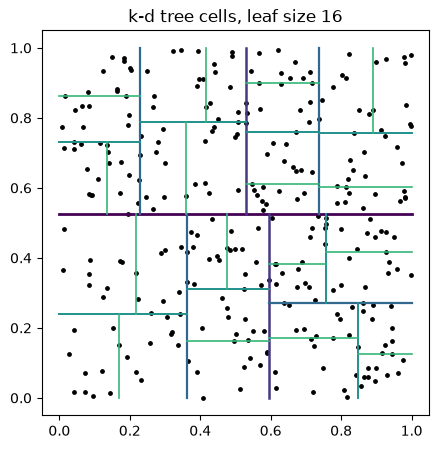

In [3]:
rng = np.random.default_rng(0)
P2 = rng.random((300, 2))
tree2 = build(P2, np.arange(300), np.ones(2))

def draw(node, box, ax, depth=0):
    if node.is_leaf:
        return
    (x0, x1), (y0, y1) = box
    t = node.threshold
    if node.axis == 0:
        ax.plot([t, t], [y0, y1], color=plt.cm.viridis(depth / 6), lw=2 - depth * .2)
        draw(node.left, ((x0, t), (y0, y1)), ax, depth + 1); draw(node.right, ((t, x1), (y0, y1)), ax, depth + 1)
    else:
        ax.plot([x0, x1], [t, t], color=plt.cm.viridis(depth / 6), lw=2 - depth * .2)
        draw(node.left, ((x0, x1), (y0, t)), ax, depth + 1); draw(node.right, ((x0, x1), (t, y1)), ax, depth + 1)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(*P2.T, s=6, color="k")
draw(tree2, ((0, 1), (0, 1)), ax)
ax.set_title("k-d tree cells, leaf size 16"); plt.show()

## 2. Searching with pruning

Keep the k best in a heap. Go first to the side of the split the query is on. On the way back ask:
can anything on the far side be closer than the current k-th best? Every far point is at least

$$ \text{gap} = w_{axis}\,|q_{axis} - \text{threshold}|^p $$

away (power distance). If `gap` is larger than the worst of the k best → skip the whole far side.

Python's `heapq` is a *min*-heap. We store `(-distance, -row)` so `heap[0]` is the **worst** kept point.

In [4]:
def kd_query(X, tree, q, k, p=2, w=None):
    w = np.ones(X.shape[1]) if w is None else w
    heap, counter = [], [0]

    def visit(node):
        if node.is_leaf:
            d = (w * np.abs(X[node.rows] - q) ** p).sum(1)
            counter[0] += len(node.rows)
            for dist, row in zip(d, node.rows):
                item = (-dist, -row)
                if len(heap) < k:
                    heapq.heappush(heap, item)
                elif item > heap[0]:                 # closer (or same distance, smaller row)
                    heapq.heapreplace(heap, item)
            return
        diff = q[node.axis] - node.threshold
        near, far = (node.left, node.right) if diff <= 0 else (node.right, node.left)
        visit(near)
        gap = w[node.axis] * abs(diff) ** p
        if len(heap) < k or gap <= -heap[0][0]:
            visit(far)

    visit(tree)
    best = sorted((-d, -r) for d, r in heap)          # nearest first, ties by row
    return np.array([r for _, r in best]), counter[0]


def linear_query(X, q, k, p=2, w=None):
    w = np.ones(X.shape[1]) if w is None else w
    d = (w * np.abs(X - q) ** p).sum(1)
    return np.argsort(d, kind="stable")[:k]

q = np.array([0.5, 0.5])
rows, n = kd_query(P2, tree2, q, k=5)
print("kd-tree :", rows, f"  ({n} of 300 distances computed)")
print("linear  :", linear_query(P2, q, k=5))

kd-tree : [223 160 268  37 146]   (38 of 300 distances computed)
linear  : [223 160 268  37 146]


In 2-D the tree computed only a small fraction of the distances. 🎉

## 3. Correctness first

A tree that prunes one branch too many still returns k points — just not the nearest. Nothing else
would notice. So we compare with the linear search on many random queries, with mixed weights
(including zeros) and both p.

In [5]:
X5 = rng.random((2000, 5))
for p in (1, 2):
    for w in (np.ones(5), np.array([2.0, 0.0, 1.0, 0.5, 1.0])):
        t = build(X5, np.arange(len(X5)), w)
        bad = sum(not np.array_equal(kd_query(X5, t, qq, 7, p, w)[0], linear_query(X5, qq, 7, p, w))
                  for qq in rng.random((300, 5)))
        print(f"p={p} w={w}: {bad} mismatches out of 300")

p=1 w=[1. 1. 1. 1. 1.]: 0 mismatches out of 300


p=1 w=[2.  0.  1.  0.5 1. ]: 0 mismatches out of 300


p=2 w=[1. 1. 1. 1. 1.]: 0 mismatches out of 300
p=2 w=[2.  0.  1.  0.5 1. ]: 0 mismatches out of 300


## 4. The real wines: how much does the tree save?

 2 features: the tree computes  2.1% of the distances
 4 features: the tree computes  8.6% of the distances


 6 features: the tree computes 17.1% of the distances


 8 features: the tree computes 28.0% of the distances


10 features: the tree computes 40.4% of the distances


12 features: the tree computes 57.1% of the distances


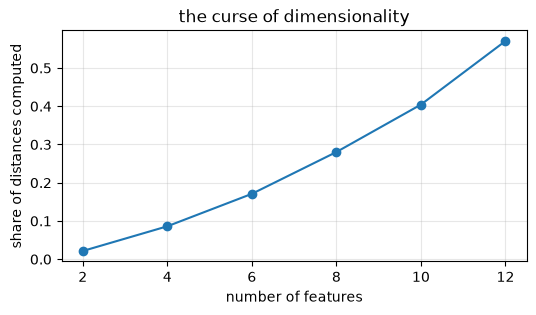

In [6]:
DATA = Path("../data")
def load(path, is_red):
    raw = np.genfromtxt(path, delimiter=";", skip_header=1)
    return np.column_stack([raw[:, :11], np.full(len(raw), float(is_red))]), raw[:, 11]
Xr, sr = load(DATA / "winequality-red.csv", 1)
Xw, sw = load(DATA / "winequality-white.csv", 0)
X = np.unique(np.column_stack([np.vstack([Xr, Xw]), np.concatenate([sr, sw])]), axis=0)
quality, X = X[:, -1], X[:, :-1]
X = (X - X.mean(0)) / X.std(0)

perm = rng.permutation(len(X))
train, queries = perm[:4250], perm[4250:4450]

# features ordered by |correlation with quality|, strongest first
corr = np.array([abs(np.corrcoef(X[:, j], quality)[0, 1]) for j in range(X.shape[1])])
by_corr = np.argsort(-corr)

dims, shares = [2, 4, 6, 8, 10, 12], []
for d in dims:
    Xd = X[:, by_corr[:d]]
    tree = build(Xd, train, np.ones(d))
    counts = [kd_query(Xd, tree, Xd[i], k=20)[1] for i in queries]
    shares.append(np.mean(counts) / len(train))
    print(f"{d:2d} features: the tree computes {shares[-1]:5.1%} of the distances")

plt.figure(figsize=(6, 3))
plt.plot(dims, shares, marker="o")
plt.xlabel("number of features"); plt.ylabel("share of distances computed")
plt.title("the curse of dimensionality"); plt.grid(alpha=.3); plt.show()

With 2–4 features the tree skips almost everything. With 12 it looks at a large part of the data,
and in Python walking the tree costs more than numpy computing **all** distances in one step:

In [7]:
import time
tree12 = build(X, train, np.ones(12))
t0 = time.perf_counter(); [kd_query(X, tree12, X[i], 20) for i in queries]; t_kd = time.perf_counter() - t0
t0 = time.perf_counter(); [linear_query(X[train], X[i], 20) for i in queries]; t_lin = time.perf_counter() - t0
print(f"per wine: kd-tree {t_kd / len(queries) * 1000:.2f} ms   linear {t_lin / len(queries) * 1000:.2f} ms")

per wine: kd-tree 4.15 ms   linear 0.88 ms


**This is a result, not a failure.** The project's claim is "here is how to *decide* whether a
k-d tree pays" — and the measurement says: not in 12 dimensions. That is why the lab station uses the
linear search. Be ready to explain the two reasons (theory 5.7): too few cuts per axis, and
distances that all look alike in high dimensions.

## ✍️ Try it yourself

1. Change `LEAF_SIZE` to 4 and 64. How do the share and the time change?
2. Replace `<=` with `<` in the pruning test. Run section 3 again with integer data
   (`rng.integers(0, 3, (2000, 5)).astype(float)`). What breaks, and why?
3. In section 4 use the *least* correlated features first. Does the curve change?

Then solve exercise 9 in `03_exercises/`.